# 02 · Análisis exploratorio de datos (EDA)

**Proyecto:** Salud mental en el sector tecnológico · De una encuesta larga a 7 preguntas
**Autor:** Hugo Nascimento · Proyecto final Data Analytics · IT Academy (Barcelona Activa)

Antes de modelar hay que **"entrevistar" a los datos**: entender su estructura, dónde faltan valores, qué datos son atípicos, cómo se distribuyen las variables y cómo se relacionan entre sí. El objetivo es asegurarme de que los datos son fiables y de que las decisiones del modelado (notebook 03, Random Forest) están justificadas.

Este notebook va después de la limpieza (notebook 01) y responde a cinco preguntas:

1. **Estructura:** ¿qué hay en la base de datos y está bien construida?
2. **Valores nulos:** ¿qué preguntas se hicieron cada año y cuánta gente las respondió?
3. **Valores atípicos (outliers):** ¿hay datos imposibles o extremos?
4. **Distribuciones:** ¿quién respondió la encuesta y cómo se reparten las respuestas clave?
5. **Relaciones:** ¿qué variables están relacionadas entre sí?

Herramientas: `pandas`, `matplotlib`, `seaborn` y `scipy`.

### Solo si ejecutas el notebook en Google Colab

Si tu ordenador bloquea alguna librería (por ejemplo, scipy por Smart App Control de Windows), puedes ejecutar este notebook en [Google Colab](https://colab.research.google.com):

1. Sube la carpeta completa del repositorio (`SPRINT13_PROYECTO_FINAL_HUGO_NASCIMENTO`) a la raíz de tu Google Drive (*Mi unidad*).
2. Abre este notebook desde Drive con *Abrir con → Google Colaboratory*.
3. Ejecuta la celda siguiente y acepta el permiso para acceder a Drive.

En tu ordenador esta celda no hace nada, así que se puede dejar tal cual.

In [1]:
import os
import sys

if "google.colab" in sys.modules:                      # solo se ejecuta dentro de Google Colab
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/SPRINT13_PROYECTO_FINAL_HUGO_NASCIMENTO/02_notebooks")
    print("Trabajando en:", os.getcwd())
else:
    print("Ejecución local: no hace falta nada.")

Ejecución local: no hace falta nada.


In [2]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

BASE = Path.cwd().parent
RUTA_ORIGINAL = BASE / "01_datos" / "originales" / "mental_health.sqlite"
RUTA_SQLITE = BASE / "01_datos" / "procesados" / "salud_mental_tech.db"
RUTA_FIGURAS = BASE / "04_figuras"
RUTA_FIGURAS.mkdir(exist_ok=True)

AZUL, NARANJA, GRIS, GRIS_CLARO = "#2a78d6", "#eb6834", "#a9a8a0", "#d9d8d1"
TINTA, TINTA2, APAGADO, REJILLA = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
AZULES = LinearSegmentedColormap.from_list("azules", ["#ffffff", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10.5, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11.5,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.facecolor": "white",
})
FUENTE = "Fuente: OSMI Mental Health in Tech Survey 2014-2019. Elaboración propia."


def guardar(fig, nombre):
    fig.savefig(RUTA_FIGURAS / nombre, dpi=200, bbox_inches="tight", facecolor="white")
    print("Guardado: 04_figuras/" + nombre)

## 1. Estructura de los datos

Cargo las 7 tablas de la base limpia y compruebo su tamaño, sus claves y cuántas preguntas responde cada persona.

In [3]:
TABLAS = ["encuestas", "temas", "preguntas", "paises", "tamanos_empresa", "personas", "respuestas"]
with sqlite3.connect(RUTA_SQLITE) as con:
    t = {nombre: pd.read_sql(f"SELECT * FROM {nombre}", con) for nombre in TABLAS}

pd.DataFrame({
    "filas": [len(t[n]) for n in TABLAS],
    "columnas": [t[n].shape[1] for n in TABLAS],
    "clave primaria": [t[n].columns[0] for n in TABLAS],
    "clave única": [t[n].iloc[:, 0].is_unique for n in TABLAS],
    "celdas nulas (%)": [round(100 * t[n].isna().mean().mean(), 1) for n in TABLAS],
}, index=TABLAS)

,filas,columnas,clave primaria,clave única,celdas nulas (%)
encuestas,5,4,encuesta_id,True,0.0
temas,8,2,tema_id,True,0.0
preguntas,105,5,pregunta_id,True,13.0
paises,83,3,pais_iso3,True,0.0
tamanos_empresa,6,2,tamano_id,True,0.0
personas,4218,8,persona_id,True,3.1
respuestas,236898,5,respuesta_id,True,4.8


In [4]:
personas, respuestas, preguntas = t["personas"], t["respuestas"], t["preguntas"]
personas = personas.merge(t["encuestas"][["encuesta_id", "anio"]], on="encuesta_id")

# Respuestas por persona: el cuestionario cambia cada año
por_persona = respuestas.groupby("persona_id").size().rename("respuestas_por_persona")
personas = personas.merge(por_persona, left_on="persona_id", right_index=True)
personas.groupby("anio")["respuestas_por_persona"].describe()[["count", "min", "50%", "max"]].astype(int)

,count,min,50%,max
anio,,,,
2014,1260,26,26,26
2016,1433,60,61,74
2017,756,76,76,76
2018,417,76,76,76
2019,352,76,76,76


**Lectura:** las 7 tablas tienen claves primarias únicas. Cada persona tiene un número de filas que depende de su año (26 en 2014, unas 60 en 2016 y 76 desde 2017), porque cada edición tiene su propio cuestionario. En 2016 varía un poco porque las preguntas de selección múltiple (diagnósticos y puesto) añaden una fila por opción marcada. La tabla `respuestas` guarda también las preguntas que la persona dejó en blanco (como `NULL`), y por eso la siguiente sección mide los nulos.

## 2. Valores nulos: qué se preguntó cada año y cuánto se respondió

En una encuesta hay dos tipos de "nulo" muy distintos:

- **La pregunta no existía ese año.** No es un fallo: el cuestionario cambia.
- **La pregunta existía, pero la persona no respondió.** Muchas veces porque no le tocaba: por ejemplo, las preguntas sobre la empresa actual no se muestran a los autónomos.

El mapa de calor muestra, para cada pregunta y año, el **% de personas de ese año con una respuesta válida**. Blanco = la pregunta no se hizo.

Guardado: 04_figuras/eda_01_cobertura_preguntas.png


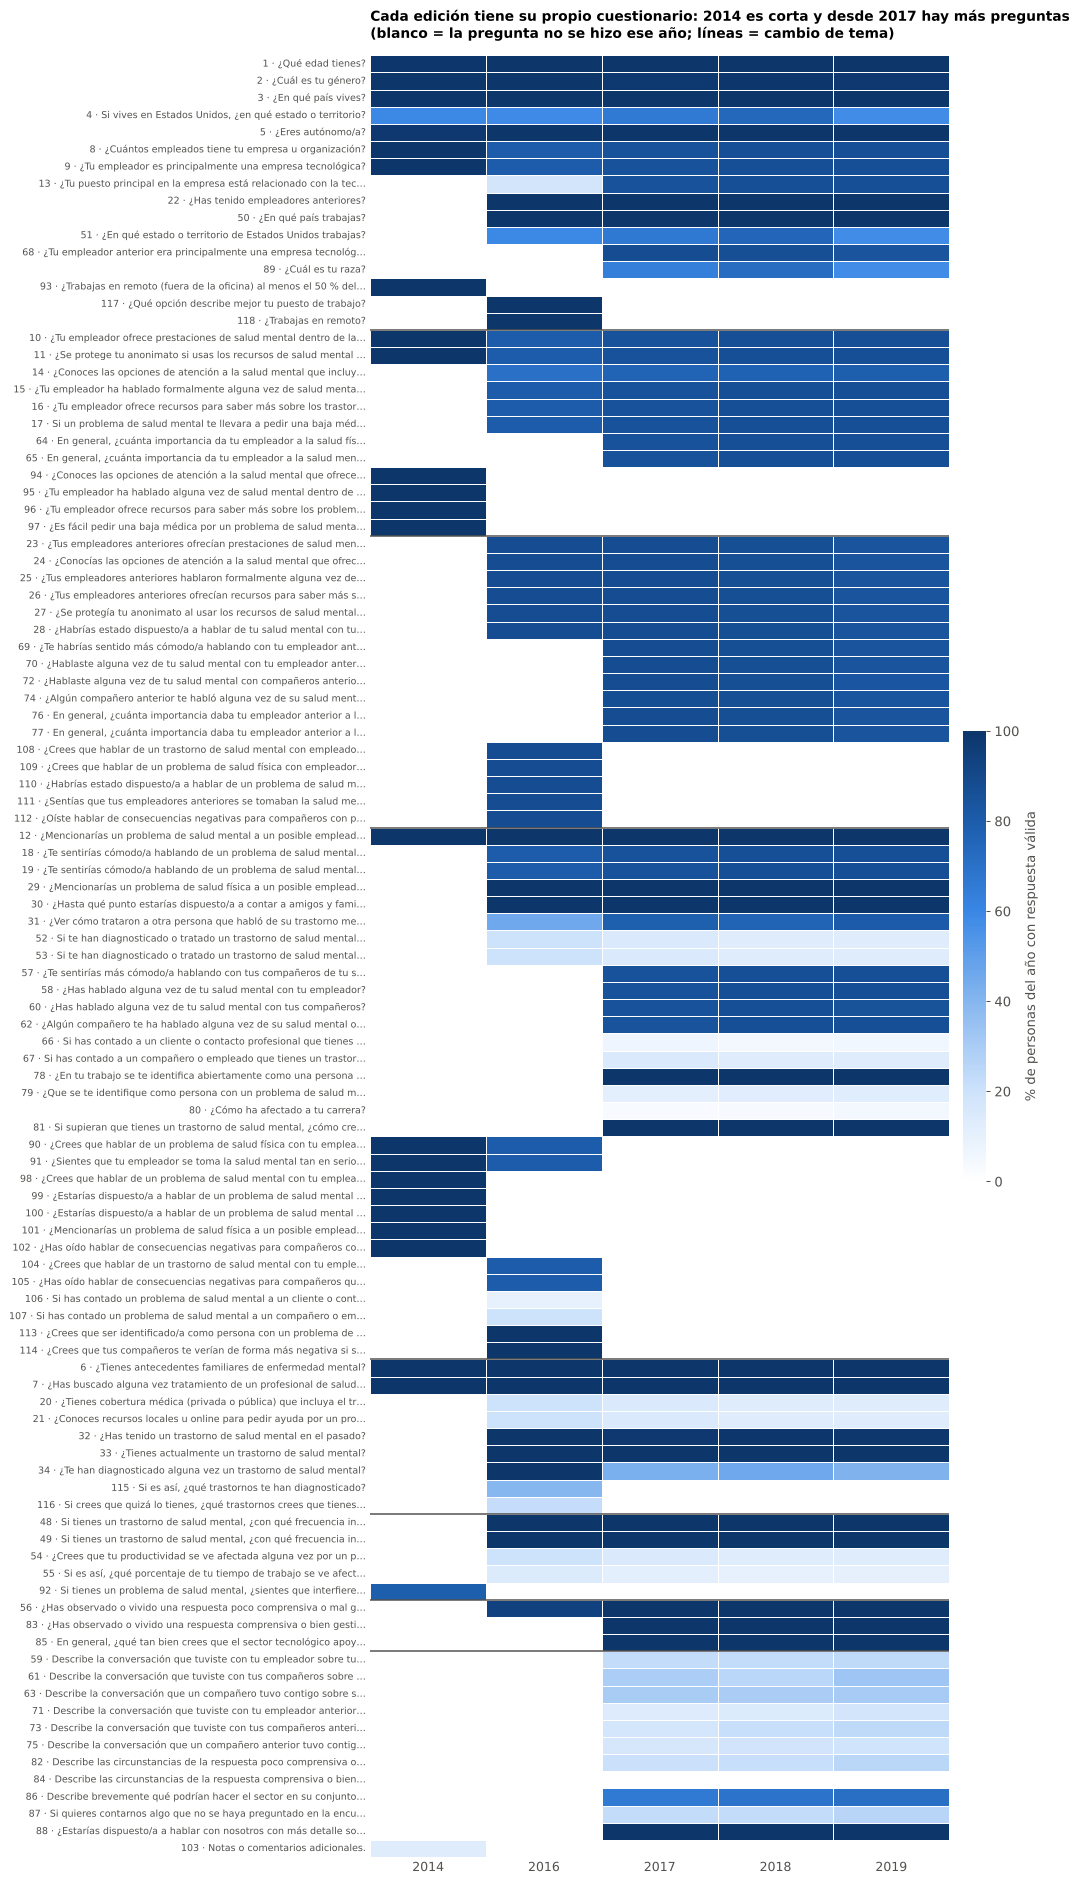

In [5]:
respuestas_anio = respuestas.merge(personas[["persona_id", "anio"]], on="persona_id")
personas_anio = personas.groupby("anio").size()
cobertura = (respuestas_anio.dropna(subset=["respuesta"])
             .groupby(["pregunta_id", "anio"])["persona_id"].nunique()
             .unstack().div(personas_anio, axis=1).mul(100))
existe = respuestas_anio.groupby(["pregunta_id", "anio"]).size().unstack().notna()
cobertura = cobertura.reindex(index=existe.index).fillna(0).where(existe)   # NaN = la pregunta no se hizo ese año

orden = preguntas.sort_values(["tema_id", "pregunta_id"])
cobertura = cobertura.reindex(orden["pregunta_id"])
etiquetas = [f"{pid} · {txt[:62]}" + ("…" if len(txt) > 62 else "")
             for pid, txt in zip(orden["pregunta_id"], orden["pregunta_es"])]

fig, ax = plt.subplots(figsize=(10, 26))
sns.heatmap(cobertura, cmap=AZULES, vmin=0, vmax=100, linewidths=0.6, linecolor="white", ax=ax,
            cbar_kws={"label": "% de personas del año con respuesta válida", "shrink": 0.25, "location": "right", "pad": 0.02},
            yticklabels=etiquetas)
ax.set_xlabel(""); ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=7.6, length=0); ax.tick_params(axis="x", length=0, labelsize=10)
# Separadores por tema
limites = orden.reset_index(drop=True).groupby("tema_id").size().cumsum().values[:-1]
for y in limites:
    ax.axhline(y, color=TINTA2, linewidth=1.2)
ax.set_title("Cada edición tiene su propio cuestionario: 2014 es corta y desde 2017 hay más preguntas\n"
             "(blanco = la pregunta no se hizo ese año; líneas = cambio de tema)", fontsize=11, pad=14)
guardar(fig, "eda_01_cobertura_preguntas.png")

In [6]:
# Resumen numérico: preguntas por año y % de respuesta en las preguntas que se hicieron
resumen_nulos = pd.DataFrame({
    "preguntas que se hicieron": existe.sum(),
    "% medio de respuesta (en las que se hicieron)": cobertura.mean().round(1),
    "preguntas con < 50 % de respuesta": (cobertura < 50).sum(),
})
resumen_nulos

,preguntas que se hicieron,% medio de respuesta (en las que se hicieron),preguntas con < 50 % de respuesta
anio,,,
2014,26,94.2,1
2016,60,76.0,12
2017,76,70.5,20
2018,76,71.0,20
2019,76,70.2,20


**Lectura de los nulos:**

- **2014 tiene solo 26 preguntas** y muchas propias (por ejemplo, el teletrabajo). Por eso casi todos los análisis empiezan en 2016.
- **2017, 2018 y 2019 comparten cuestionario**: se pueden analizar juntos sin problema.
- Las preguntas con poca respuesta **no son errores**: son preguntas condicionadas. Las de empresas anteriores solo las ve quien ha tenido otros empleos, y las de productividad (54 y 55), solo los autónomos. Las de texto libre son opcionales.
- **Decisión para el modelado:** el Random Forest usa solo 2017-2019, que comparten cuestionario, y los porcentajes se calculan sobre quien respondió. No invento respuestas: en el modelo, «sin respuesta» es un valor más (−1 o una categoría propia), porque inventar respuestas en una encuesta de opinión introduciría un sesgo.

## 3. Valores atípicos (outliers): la edad

La edad es la única variable numérica abierta (la persona escribe el número), así que es donde pueden aparecer valores imposibles. Comparo la edad **original** (antes de limpiar) con la **limpia**.

In [7]:
with sqlite3.connect(RUTA_ORIGINAL) as con:
    edad_original = pd.to_numeric(pd.read_sql("SELECT AnswerText FROM Answer WHERE QuestionID = 1", con)["AnswerText"],
                                  errors="coerce")
edad_original = edad_original.replace(-1, np.nan)    # -1 es el código de "no respondió", no una edad
edad_limpia = personas["edad"].dropna()

q1, q3 = edad_limpia.quantile([0.25, 0.75])
iqr = q3 - q1
limite_inf, limite_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr

print("Edad original: valores más bajos ->", sorted(edad_original.dropna().astype(int))[:6])
print("Edad original: valores más altos ->", sorted(edad_original.dropna().astype(int))[-6:])
print(f"Valores imposibles (< 18 o > 75) que pasaron a nulo: {((edad_original < 18) | (edad_original > 75)).sum()}")
print(f"Regla del rango intercuartílico (IQR) sobre la edad limpia: Q1 = {q1:.0f}, Q3 = {q3:.0f}, "
      f"límites = {limite_inf:.0f} y {limite_sup:.0f} años")
print(f"Edades limpias fuera de esos límites: {((edad_limpia < limite_inf) | (edad_limpia > limite_sup)).sum()}")
edad_limpia.describe().round(1).to_frame("edad limpia").T

Edad original: valores más bajos -> [-29, 0, 3, 5, 8, 11]
Edad original: valores más altos -> [70, 72, 74, 99, 323, 329]
Valores imposibles (< 18 o > 75) que pasaron a nulo: 11
Regla del rango intercuartílico (IQR) sobre la edad limpia: Q1 = 28, Q3 = 38, límites = 13 y 53 años
Edades limpias fuera de esos límites: 110


,count,mean,std,min,25%,50%,75%,max
edad limpia,4202.0,33.9,8.1,18.0,28.0,33.0,38.0,74.0


Guardado: 04_figuras/eda_02_edad_outliers.png


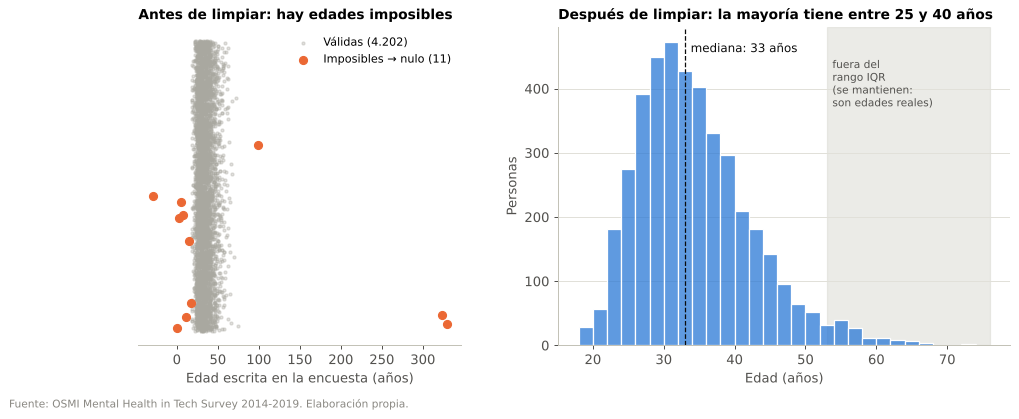

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [1, 1.4], "wspace": 0.25})

# Izquierda: original, con los valores imposibles en naranja
validas = edad_original[(edad_original >= 18) & (edad_original <= 75)]
imposibles = edad_original[(edad_original < 18) | (edad_original > 75)]
rng = np.random.default_rng(0)
ax1.scatter(validas, rng.uniform(-0.3, 0.3, len(validas)), s=6, color=GRIS, alpha=0.35, label=f"Válidas ({len(validas):,})".replace(",", "."))
ax1.scatter(imposibles, rng.uniform(-0.3, 0.3, len(imposibles)), s=40, color=NARANJA, label=f"Imposibles → nulo ({len(imposibles)})")
ax1.set_yticks([]); ax1.spines["left"].set_visible(False)
ax1.set_xlabel("Edad escrita en la encuesta (años)")
ax1.set_title("Antes de limpiar: hay edades imposibles", fontsize=11)
ax1.legend(frameon=False, loc="upper right", fontsize=9)

# Derecha: limpia, histograma y caja
sns.histplot(edad_limpia, bins=range(18, 76, 2), color=AZUL, edgecolor="white", ax=ax2)
ax2.axvline(edad_limpia.median(), color=TINTA, linestyle="--", linewidth=1)
ax2.text(edad_limpia.median() + 0.8, ax2.get_ylim()[1] * 0.92, f"mediana: {edad_limpia.median():.0f} años", fontsize=9.5, color=TINTA)
ax2.axvspan(limite_sup, 76, color=GRIS_CLARO, alpha=0.5, zorder=0)
ax2.text(limite_sup + 0.8, ax2.get_ylim()[1] * 0.75, "fuera del\nrango IQR\n(se mantienen:\nson edades reales)", fontsize=8.5, color=TINTA2)
ax2.set_xlabel("Edad (años)"); ax2.set_ylabel("Personas")
ax2.set_title("Después de limpiar: la mayoría tiene entre 25 y 40 años", fontsize=11)
ax2.grid(axis="y", color=REJILLA); ax2.set_axisbelow(True)
fig.text(0.01, -0.04, FUENTE, fontsize=8.5, color=APAGADO)
guardar(fig, "eda_02_edad_outliers.png")

**Lectura de los outliers:**

- En los datos originales, el `-1` significa "no respondió" (no es una edad) y lo trato como nulo. Además hay **edades imposibles** (-29, 0, 3, 99, 323, 329…). Son errores al escribir y en la limpieza también pasaron a nulo.
- Con la regla del rango intercuartílico (IQR), algunas edades limpias quedan fuera por arriba (personas de más de 50 años). **No las elimino**: son edades reales, y simplemente hay pocas personas mayores en el sector. Un outlier estadístico no es lo mismo que un error.
- **Decisión para el modelado:** en el Random Forest la edad es la única variable numérica y la escalo con z-score. Los valores extremos no le afectan, porque un árbol solo pregunta «¿es mayor o menor que…?».

## 4. Distribuciones: quién respondió y cómo se reparten las respuestas clave

### 4.1 Perfil de la muestra

Guardado: 04_figuras/eda_03_perfil_muestra.png


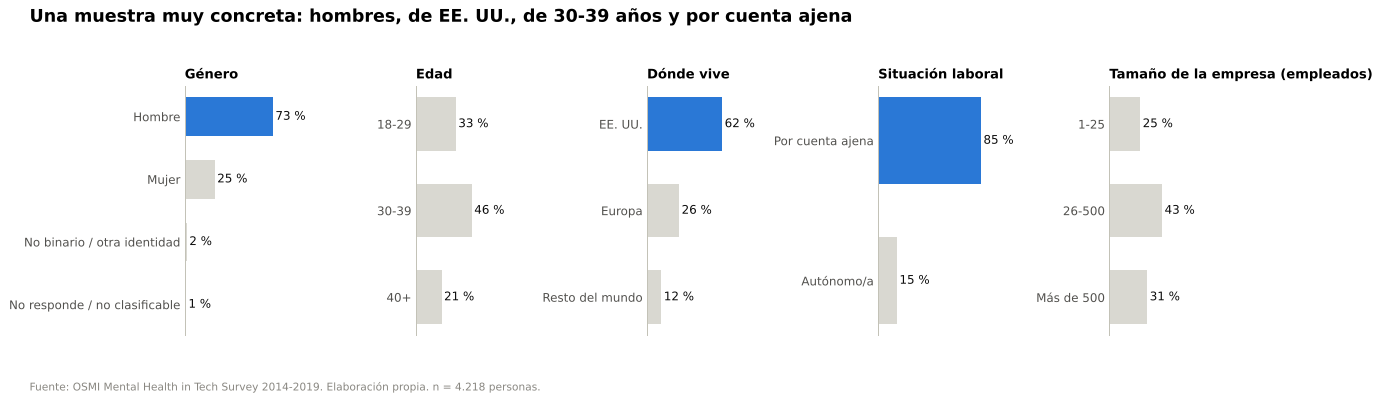

In [9]:
TAM = {"1-5": "1-25", "6-25": "1-25", "26-100": "26-500", "100-500": "26-500", "500-1000": "Más de 500", "Más de 1000": "Más de 500"}
perfil = personas.merge(t["paises"][["pais_iso3", "region"]], on="pais_iso3", how="left") \
                 .merge(t["tamanos_empresa"], on="tamano_id", how="left")
perfil["zona"] = np.where(perfil["pais_iso3"] == "USA", "EE. UU.", np.where(perfil["region"] == "Europa", "Europa",
                          np.where(perfil["pais_iso3"].isna(), None, "Resto del mundo")))
perfil["tramo_edad"] = pd.cut(perfil["edad"], [17, 29, 39, 75], labels=["18-29", "30-39", "40+"]).astype(object)
perfil["situacion"] = perfil["autonomo"].map({1: "Autónomo/a", 0: "Por cuenta ajena"})
perfil["tamano"] = perfil["tramo_empleados"].map(TAM)

VARIABLES_PERFIL = {"genero": "Género", "tramo_edad": "Edad", "zona": "Dónde vive", "situacion": "Situación laboral",
                    "tamano": "Tamaño de la empresa (empleados)"}
fig, axes = plt.subplots(1, 5, figsize=(15, 3.6), gridspec_kw={"wspace": 0.9})
for ax, (col, titulo) in zip(axes, VARIABLES_PERFIL.items()):
    pct = perfil[col].value_counts(normalize=True).mul(100)
    if col == "tramo_edad":
        pct = pct.reindex(["18-29", "30-39", "40+"])
    elif col == "tamano":
        pct = pct.reindex(["1-25", "26-500", "Más de 500"])
    colores = [AZUL] + [GRIS_CLARO] * (len(pct) - 1) if col not in ("tramo_edad", "tamano") else [GRIS_CLARO] * len(pct)
    ax.barh(pct.index[::-1], pct.values[::-1], color=colores[::-1], height=0.62)
    for y, v in enumerate(pct.values[::-1]):
        ax.text(v + 2, y, f"{v:.0f} %", va="center", fontsize=9.5, color=TINTA)
    ax.set_xlim(0, 100); ax.xaxis.set_visible(False); ax.spines["bottom"].set_visible(False)
    ax.tick_params(axis="y", length=0, labelsize=9.5)
    ax.set_title(titulo, fontsize=10.5)
fig.suptitle("Una muestra muy concreta: hombres, de EE. UU., de 30-39 años y por cuenta ajena", x=0.01, ha="left",
             fontsize=14, fontweight="bold", y=1.12)
fig.text(0.01, -0.06, FUENTE + f" n = {len(perfil):,} personas.".replace(",", "."), fontsize=8.5, color=APAGADO)
guardar(fig, "eda_03_perfil_muestra.png")

In [10]:
# ¿Cambia el perfil de un año a otro? Si cambia mucho, comparar años sin controlar sería engañoso
pd.DataFrame({
    "personas": perfil.groupby("anio").size(),
    "% mujeres": perfil.groupby("anio")["genero"].apply(lambda s: 100 * (s == "Mujer").mean()).round(1),
    "% EE. UU.": perfil.groupby("anio")["zona"].apply(lambda s: 100 * (s == "EE. UU.").mean()).round(1),
    "% autónomos": perfil.groupby("anio")["autonomo"].mean().mul(100).round(1),
    "edad mediana": perfil.groupby("anio")["edad"].median(),
})

,personas,% mujeres,% EE. UU.,% autónomos,edad mediana
anio,,,,,
2014,1260,19.9,59.6,11.8,31.0
2016,1433,23.9,58.6,20.0,33.0
2017,756,29.4,65.7,14.9,34.0
2018,417,30.5,74.8,13.4,34.0
2019,352,28.4,58.0,13.6,34.0


**Lectura del perfil:**

- La muestra es **muy poco diversa**: unas tres cuartas partes son hombres, más de seis de cada diez viven en EE. UU. y la mayoría trabaja por cuenta ajena. Los resultados describen a este perfil, no a todo el sector.
- **El perfil cambia entre años:** las mujeres pasan del 20 % en 2014 a cerca del 30 % en 2017-2019, y el peso de EE. UU. varía entre el 58 % y el 75 %. Si comparo años sin tenerlo en cuenta, podría confundir un cambio real con un cambio en quién responde. Por eso en el Random Forest el género, la zona y el año entran como variables.
- Las personas **no binarias** son muy pocas (alrededor del 2 %): sus resultados tendrán intervalos de confianza muy anchos.

### 4.2 Las variables que se van a modelar

Guardado: 04_figuras/eda_04_variables_clave.png


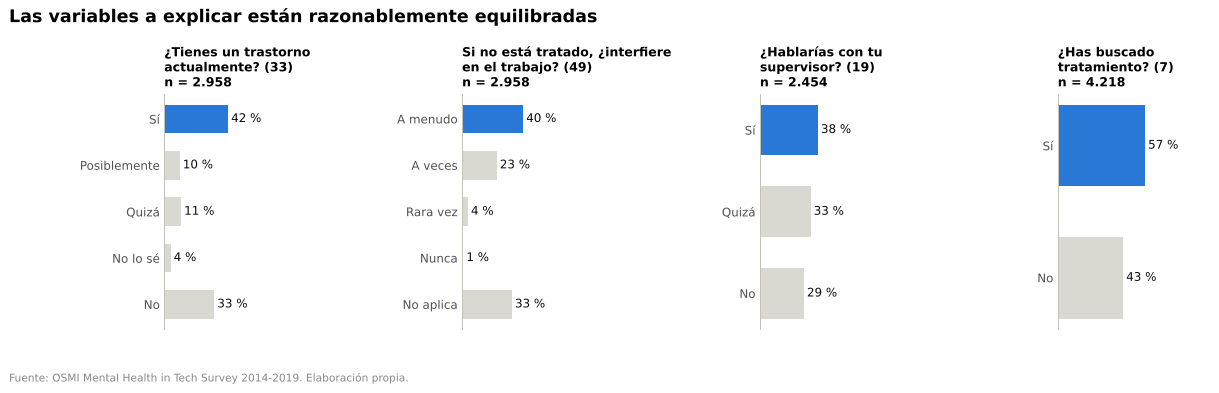

In [11]:
CLAVE = {
    "trastorno_actual": ("¿Tienes un trastorno\nactualmente? (33)", ["Sí", "Posiblemente", "Quizá", "No lo sé", "No"]),
    "interfiere_sin_tratamiento": ("Si no está tratado, ¿interfiere\nen el trabajo? (49)", ["A menudo", "A veces", "Rara vez", "Nunca", "No aplica"]),
    "comodo_hablar_supervisor": ("¿Hablarías con tu\nsupervisor? (19)", ["Sí", "Quizá", "No"]),
    "tratamiento_alguna_vez": ("¿Has buscado\ntratamiento? (7)", ["Sí", "No"]),
}
codigo_a_id = preguntas.dropna(subset=["codigo"]).set_index("codigo")["pregunta_id"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), gridspec_kw={"wspace": 0.95})
for ax, (cod, (titulo, orden_cat)) in zip(axes, CLAVE.items()):
    s = respuestas.loc[respuestas["pregunta_id"] == codigo_a_id[cod], "respuesta"].dropna()
    pct = s.value_counts(normalize=True).mul(100).reindex(orden_cat).fillna(0)
    ax.barh(pct.index[::-1], pct.values[::-1], color=[GRIS_CLARO] * (len(pct) - 1) + [AZUL], height=0.62)
    for y, v in enumerate(pct.values[::-1]):
        ax.text(v + 2, y, f"{v:.0f} %", va="center", fontsize=9.5, color=TINTA)
    ax.set_xlim(0, 100); ax.xaxis.set_visible(False); ax.spines["bottom"].set_visible(False)
    ax.tick_params(axis="y", length=0, labelsize=9.5)
    ax.set_title(titulo + "\nn = " + f"{len(s):,}".replace(",", "."), fontsize=10)
fig.suptitle("Las variables a explicar están razonablemente equilibradas", x=0.01, ha="left", fontsize=14,
             fontweight="bold", y=1.16)
fig.text(0.01, -0.06, FUENTE, fontsize=8.5, color=APAGADO)
guardar(fig, "eda_04_variables_clave.png")

**Lectura:** para un modelo de clasificación conviene que la variable a predecir no esté muy desequilibrada (por ejemplo, 95 % frente a 5 %). Aquí las proporciones son razonables: trastorno Sí frente a No (56 % / 44 %) e interfiere "a menudo" frente al resto (59 % / 41 %, sin "No aplica"). Hablar con el supervisor queda en 38 % frente al resto, pero en el Random Forest solo uso a quien responde «Sí» o «No» (sin «Quizá»), y entonces queda en 58 % / 42 %. En cambio, la pregunta 54 (productividad afectada) no sirve: el 93 % responde que sí.

### 4.3 Las escalas numéricas

Guardado: 04_figuras/eda_05_escalas.png


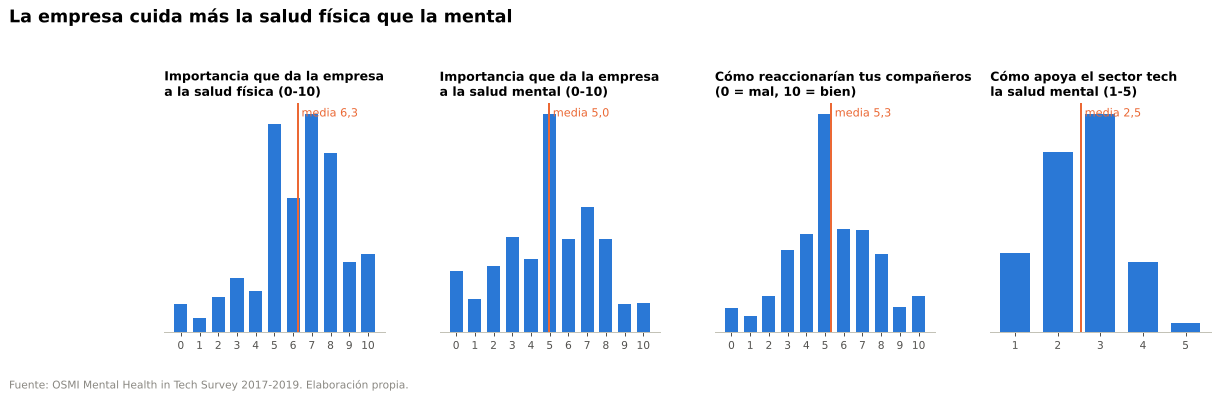

In [12]:
ESCALAS = {64: "Importancia que da la empresa\na la salud física (0-10)", 65: "Importancia que da la empresa\na la salud mental (0-10)",
           81: "Cómo reaccionarían tus compañeros\n(0 = mal, 10 = bien)", 85: "Cómo apoya el sector tech\nla salud mental (1-5)"}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.3), gridspec_kw={"wspace": 0.25})
medias = {}
for ax, (pid, titulo) in zip(axes, ESCALAS.items()):
    s = pd.to_numeric(respuestas.loc[respuestas["pregunta_id"] == pid, "respuesta"], errors="coerce").dropna()
    medias[pid] = s.mean()
    cuenta = s.value_counts().sort_index()
    ax.bar(cuenta.index, cuenta.values, color=AZUL, width=0.7)
    ax.axvline(s.mean(), color=NARANJA, linewidth=1.6)
    ax.text(s.mean(), ax.get_ylim()[1] * 0.98, f" media {s.mean():.1f}".replace(".", ","), color=NARANJA, fontsize=9, va="top")
    ax.set_title(titulo, fontsize=10)
    ax.set_xticks(cuenta.index); ax.tick_params(labelsize=8.5)
    ax.yaxis.set_visible(False); ax.spines["left"].set_visible(False)
fig.suptitle("La empresa cuida más la salud física que la mental", x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.2)
fig.text(0.01, -0.08, "Fuente: OSMI Mental Health in Tech Survey 2017-2019. Elaboración propia.", fontsize=8.5, color=APAGADO)
guardar(fig, "eda_05_escalas.png")

**Lectura:** las escalas de 0 a 10 tienen un pico claro en el 5 (la respuesta "neutral"), algo típico de las encuestas. La importancia que da la empresa a la **salud mental** tiene una media claramente más baja que la de la **salud física**. En el Random Forest uso estas escalas como **ordinales** (0, 1, 2… hasta 10), sin escalar, porque nadie puede responder «5,5». En los gráficos descriptivos a veces las agrupo en baja (0-3), media (4-6) y alta (7-10) para leerlas mejor.

## 5. Relaciones entre variables

### 5.1 Correlación entre las escalas numéricas (Spearman)

Para variables numéricas se usa `DataFrame.corr()`. Uso el método de **Spearman** en lugar de Pearson porque son escalas ordinales (un 6 no es "el doble" de un 3) y no siguen una distribución normal.

Guardado: 04_figuras/eda_06_correlacion_spearman.png


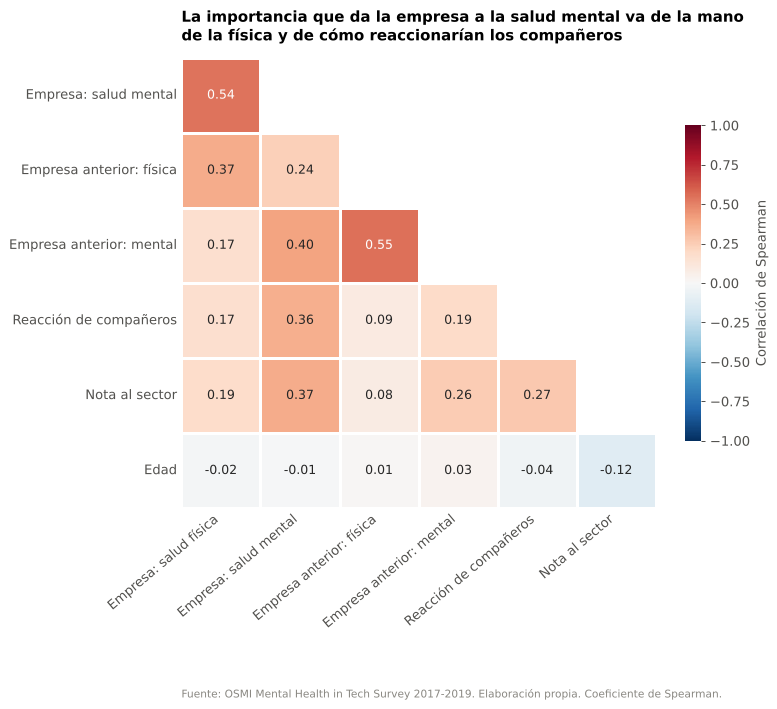

In [13]:
ancho = respuestas[respuestas["pregunta_id"].isin([64, 65, 76, 77, 81, 85])].pivot(index="persona_id", columns="pregunta_id", values="respuesta")
ancho = ancho.apply(pd.to_numeric, errors="coerce").merge(personas.set_index("persona_id")[["edad"]], left_index=True, right_index=True)
ancho.columns = ["Empresa: salud física", "Empresa: salud mental", "Empresa anterior: física", "Empresa anterior: mental",
                 "Reacción de compañeros", "Nota al sector", "Edad"]
correlacion = ancho.corr(method="spearman")

fig, ax = plt.subplots(figsize=(8.5, 6.5))
correlacion = correlacion.iloc[1:, :-1]                  # sin la diagonal (siempre 1)
mascara = np.triu(np.ones_like(correlacion, dtype=bool), k=1)
sns.heatmap(correlacion, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=1, linecolor="white", ax=ax, cbar_kws={"label": "Correlación de Spearman", "shrink": 0.7},
            annot_kws={"fontsize": 10})
ax.tick_params(length=0)
ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right")
ax.set_title("La importancia que da la empresa a la salud mental va de la mano\nde la física y de cómo reaccionarían los compañeros",
             fontsize=12, pad=14)
ax.text(0, -0.42, "Fuente: OSMI Mental Health in Tech Survey 2017-2019. Elaboración propia. Coeficiente de Spearman.",
        transform=ax.transAxes, fontsize=8.5, color=APAGADO)
guardar(fig, "eda_06_correlacion_spearman.png")

### 5.2 Relación entre variables categóricas (V de Cramér)

Casi todas las variables de la encuesta son categorías, y ahí `.corr()` no sirve. El equivalente es la **V de Cramér**, que sale del chi-cuadrado y va de 0 (sin relación) a 1 (relación total). Como referencia: ≈ 0,1 débil, ≈ 0,2-0,3 moderada y > 0,3 fuerte.

Calculo la V para cada par de las variables que entran en los modelos. Cada par usa las personas que respondieron las dos preguntas, así que el número de personas varía de un par a otro.

Guardado: 04_figuras/eda_07_v_cramer.png


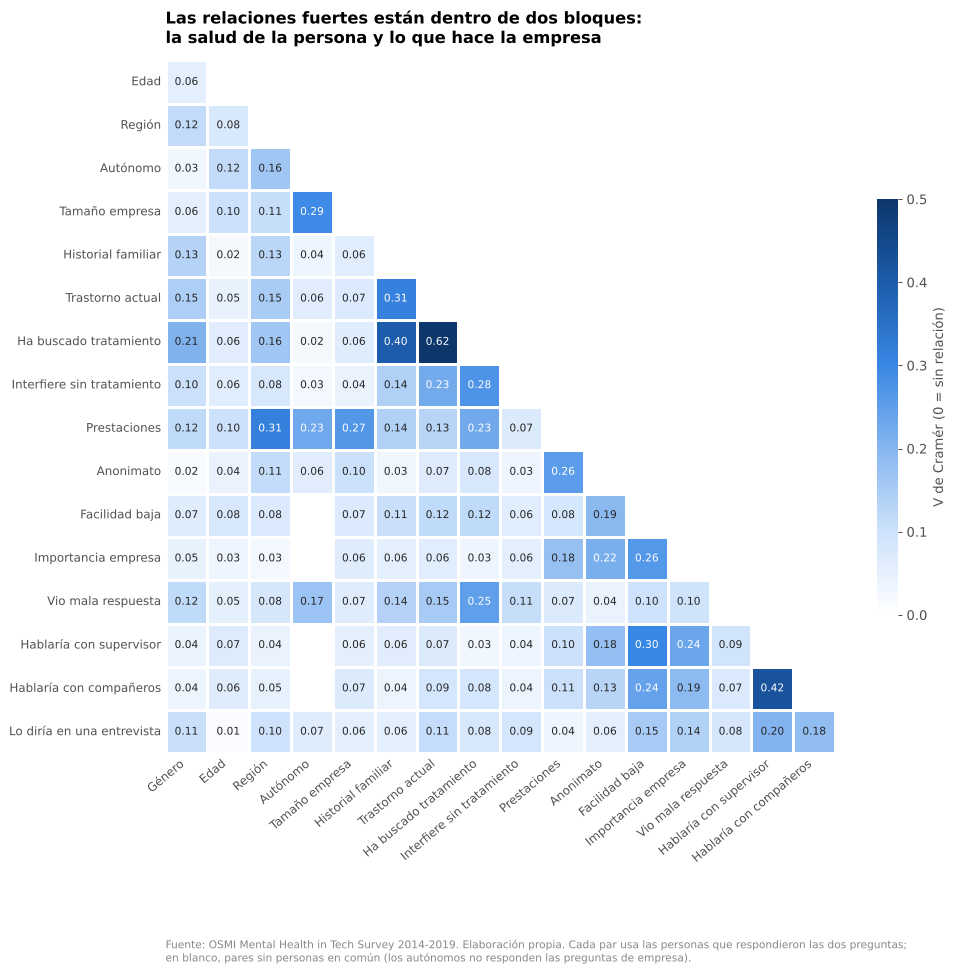

In [14]:
def respuesta(codigo):
    s = respuestas[respuestas["pregunta_id"] == codigo_a_id[codigo]].set_index("persona_id")["respuesta"]
    return s.reindex(personas["persona_id"]).values

cat = pd.DataFrame(index=personas["persona_id"])
cat["Género"] = perfil.set_index("persona_id")["genero"].where(lambda s: s != "No responde / no clasificable")
cat["Edad"] = perfil.set_index("persona_id")["tramo_edad"]
cat["Región"] = perfil.set_index("persona_id")["zona"]
cat["Autónomo"] = perfil.set_index("persona_id")["situacion"]
cat["Tamaño empresa"] = perfil.set_index("persona_id")["tamano"]
cat["Historial familiar"] = respuesta("historial_familiar")
cat["Trastorno actual"] = respuesta("trastorno_actual")
cat["Ha buscado tratamiento"] = respuesta("tratamiento_alguna_vez")
cat["Interfiere sin tratamiento"] = pd.Series(respuesta("interfiere_sin_tratamiento"), index=cat.index).replace("No aplica", np.nan)
cat["Prestaciones"] = respuesta("prestaciones_salud_mental")
cat["Anonimato"] = respuesta("anonimato_protegido")
cat["Facilidad baja"] = respuesta("facilidad_baja_medica")
cat["Importancia empresa"] = pd.cut(pd.to_numeric(pd.Series(respuesta("importancia_empresa_salud_mental"), index=cat.index), errors="coerce"),
                                    [-1, 3, 6, 10], labels=["Baja", "Media", "Alta"]).astype(object)
cat["Vio mala respuesta"] = respuesta("vio_respuesta_negativa")
cat["Hablaría con supervisor"] = respuesta("comodo_hablar_supervisor")
cat["Hablaría con compañeros"] = respuesta("comodo_hablar_companeros")
cat["Lo diría en una entrevista"] = respuesta("lo_contaria_en_entrevista")


def v_cramer(a, b):
    tabla = pd.crosstab(a, b)
    if min(tabla.shape) < 2:
        return np.nan
    chi2 = stats.chi2_contingency(tabla)[0]
    return np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))

columnas = cat.columns
matriz_v = pd.DataFrame([[v_cramer(cat[a], cat[b]) if a != b else 1.0 for b in columnas] for a in columnas],
                        index=columnas, columns=columnas)

fig, ax = plt.subplots(figsize=(12, 10))
matriz_dibujo = matriz_v.iloc[1:, :-1]                   # sin la diagonal (siempre 1)
sns.heatmap(matriz_dibujo, mask=np.triu(np.ones_like(matriz_dibujo, dtype=bool), k=1), annot=True, fmt=".2f", cmap=AZULES,
            vmin=0, vmax=0.5, linewidths=1, linecolor="white", ax=ax, annot_kws={"fontsize": 8.5},
            cbar_kws={"label": "V de Cramér (0 = sin relación)", "shrink": 0.6})
ax.tick_params(length=0, labelsize=9.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right")
ax.set_title("Las relaciones fuertes están dentro de dos bloques:\n"
             "la salud de la persona y lo que hace la empresa", fontsize=13, pad=14)
ax.text(0, -0.3, "Fuente: OSMI Mental Health in Tech Survey 2014-2019. Elaboración propia. Cada par usa las personas que "
        "respondieron las dos preguntas;\nen blanco, pares sin personas en común (los autónomos no responden las preguntas de empresa).",
        transform=ax.transAxes, fontsize=8.5, color=APAGADO)
guardar(fig, "eda_07_v_cramer.png")

In [15]:
# Las 12 relaciones más fuertes
pares = matriz_v.where(np.tril(np.ones_like(matriz_v, dtype=bool), k=-1)).stack().sort_values(ascending=False)
pares.head(12).round(3).rename("V de Cramér").to_frame()

,,V de Cramér
Ha buscado tratamiento,Trastorno actual,0.615
Hablaría con compañeros,Hablaría con supervisor,0.423
Ha buscado tratamiento,Historial familiar,0.400
Prestaciones,Región,0.315
Trastorno actual,Historial familiar,0.313
Hablaría con supervisor,Facilidad baja,0.301
Tamaño empresa,Autónomo,0.294
Interfiere sin tratamiento,Ha buscado tratamiento,0.275
Prestaciones,Tamaño empresa,0.266
Importancia empresa,Facilidad baja,0.264


**Lectura de las relaciones:**

- Hay **dos bloques** de relaciones fuertes:
    - **Salud personal:** antecedentes familiares ↔ trastorno actual ↔ haber buscado tratamiento ↔ interferencia en el trabajo.
    - **Empresa y hablar:** importancia que da la empresa, facilidad para pedir la baja y anonimato ↔ hablar con el supervisor y con los compañeros.
- Las más fuertes son **haber buscado tratamiento ↔ trastorno actual** (V = 0,62) y **hablaría con el supervisor ↔ con los compañeros** (V = 0,42).
- **Prestaciones ↔ región** (V = 0,32) también destaca: en EE. UU. el seguro médico va con la empresa, así que allí es más habitual tener prestaciones de salud mental.
- Entre los dos bloques las relaciones son débiles: **tener un trastorno casi no tiene que ver con atreverse a hablar**. Lo que lo explica es la empresa. Esta idea es la base de mi pregunta: qué puede hacer la empresa para que la gente hable.
- Las variables de perfil (género, región) tienen relaciones moderadas con la salud y débiles con hablar.
- **Ojo, correlación no es causalidad:** que dos variables vayan juntas no dice cuál causa cuál. Por ejemplo, haber buscado tratamiento va unido a más interferencia en el trabajo, pero lo más probable es que quien tiene un trastorno más grave busque más ayuda, y no al revés. Por eso, en el Random Forest (notebook 03) hablo de qué preguntas **ayudan a predecir**, no de qué causa qué.
- **Multicolinealidad:** "Hablaría con supervisor" y "Hablaría con compañeros" están muy relacionadas (miden casi lo mismo), así que no las uso juntas en un modelo. Lo mismo pasa con trastorno actual, trastorno pasado y diagnóstico.

## 6. Conclusiones del EDA y decisiones para el modelado

| Lo que he visto | Decisión |
|---|---|
| El cuestionario cambia cada año; 2014 es muy corto | El Random Forest usa 2017-2019, que comparten cuestionario; el año entra como variable |
| Muchas preguntas son condicionadas (empleados, autónomos, empresas anteriores) | Solo empleados por cuenta ajena; los % se calculan sobre quien respondió y en el modelo «sin respuesta» es un valor propio |
| Las preguntas 54 y 55 solo las respondieron autónomos, y la 54 está desequilibrada (93 % sí) | Fuera de los modelos |
| Edades imposibles en el original | Ya pasaron a nulo en la limpieza; en el modelo, la edad con z-score |
| Muestra con mucho peso de hombres y de EE. UU. | Género y zona entran en el modelo; lo explico como limitación |
| Personas no binarias ≈ 2 % y raza con un 91 % de personas blancas | Las mantengo, pero no saco conclusiones de grupos tan pequeños |
| Escalas 0-10 con un pico en el 5 | En el modelo, ordinales (0-10) sin escalar |
| Dos bloques de variables relacionadas, débiles entre sí | El objetivo central es la 19 (hablar con el supervisor); la 33 (tener un trastorno) me sirve de contraste |
| Variables casi redundantes (supervisor y compañeros; trastorno actual, pasado y diagnóstico) | Las quito del modelo de su «gemela» (por ejemplo, la 18 en el modelo 19) |

Con esto, los datos son fiables para el uso que les voy a dar, y las decisiones del notebook 03 quedan justificadas.